# TSVD Regularization for Shack-Hartmann Wavefront Reconstruction

This notebook studies truncated singular value decomposition (TSVD) regularization for modal wavefront reconstruction.

The goal is to demonstrate the trade-off between:

- fitting high-order atmospheric wavefront structure,
- avoiding noise amplification,
- retaining stable singular directions,
- improving the residual wavefront RMS and Strehl ratio.

This notebook intentionally uses a more challenging reconstruction configuration:

- higher Zernike correction order,
- fewer Shack-Hartmann lenslets,
- non-zero slope measurement noise.

This makes the role of TSVD regularization more visible.

In [1]:
from pathlib import Path
import sys
import importlib

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "zernike.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /Users/xuhan/Desktop/AO


In [13]:
import numpy as np
import matplotlib.pyplot as plt

import zernike
import phase_screen
import reconstruction

importlib.reload(zernike)
importlib.reload(phase_screen)
importlib.reload(reconstruction)

from zernike import (
    make_pupil_grid,
    generate_zernike_modes,
)

from phase_screen import fourier_phase_screen

from reconstruction import (
    build_response_matrix,
    measure_slopes,
    residual_wavefront,
    rms,
)

In [14]:
def compute_psf_from_phase(phase_rad, mask, pad_factor=4):
    """
    Compute focal-plane PSF from pupil-plane phase.

    Parameters
    ----------
    phase_rad : ndarray
        Residual phase in radians.
    mask : ndarray
        Pupil mask.
    pad_factor : int
        Zero-padding factor for focal-plane sampling.

    Returns
    -------
    psf : ndarray
        Normalized PSF.
    """
    N = phase_rad.shape[0]

    pupil_field = np.zeros_like(phase_rad, dtype=complex)
    phase_clean = np.nan_to_num(phase_rad, nan=0.0)

    pupil_field[mask] = np.exp(1j * phase_clean[mask])

    pad_N = pad_factor * N
    padded = np.zeros((pad_N, pad_N), dtype=complex)

    start = (pad_N - N) // 2
    end = start + N

    padded[start:end, start:end] = pupil_field

    focal_field = np.fft.fftshift(
        np.fft.fft2(
            np.fft.ifftshift(padded)
        )
    )

    psf = np.abs(focal_field) ** 2
    psf /= np.sum(psf)

    return psf


def strehl_ratio(phase_rad, mask, pad_factor=4):
    """
    Compute approximate Strehl ratio.

    Strehl = peak aberrated PSF / peak diffraction-limited PSF
    """
    psf_aberrated = compute_psf_from_phase(
        phase_rad,
        mask,
        pad_factor=pad_factor,
    )

    psf_ideal = compute_psf_from_phase(
        np.zeros_like(phase_rad),
        mask,
        pad_factor=pad_factor,
    )

    return np.max(psf_aberrated) / np.max(psf_ideal)

In [15]:
# -------------------------
# Grid and atmosphere
# -------------------------
N = 256
diameter = 1.0

# -------------------------
# More challenging reconstruction setup
# -------------------------
max_radial_order = 14
n_lenslets = 14
noise_std = 0.05

# -------------------------
# Atmospheric phase-screen parameters
# -------------------------
r0 = 0.20
L0 = 25.0
atmosphere_seed = 4
target_rms_rad = 1.0

print("Simulation setup")
print("----------------")
print(f"N:                  {N}")
print(f"diameter:           {diameter}")
print(f"max_radial_order:   {max_radial_order}")
print(f"n_lenslets:         {n_lenslets}")
print(f"slope noise std:    {noise_std}")
print(f"r0:                 {r0}")
print(f"L0:                 {L0}")
print(f"target RMS phase:   {target_rms_rad} rad")

Simulation setup
----------------
N:                  256
diameter:           1.0
max_radial_order:   14
n_lenslets:         14
slope noise std:    0.05
r0:                 0.2
L0:                 25.0
target RMS phase:   1.0 rad


In [16]:
X, Y, rho, theta, mask, dx = make_pupil_grid(
    N=N,
    diameter=diameter,
)

W_atm, _, _, _ = fourier_phase_screen(
    N=N,
    delta=dx,
    r0=r0,
    L0=L0,
    diameter=diameter,
    seed=atmosphere_seed,
    target_rms_rad=target_rms_rad,
)

print(f"Atmospheric wavefront RMS: {rms(W_atm, mask):.4f} rad")

Atmospheric wavefront RMS: 0.9999 rad


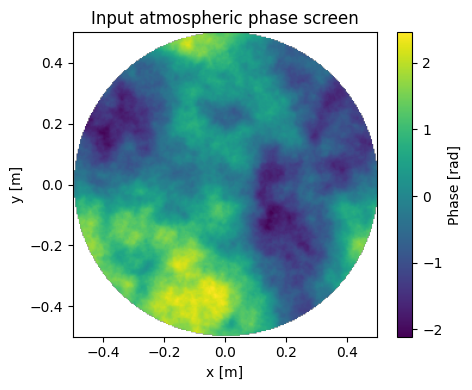

In [17]:
extent = [
    np.nanmin(X),
    np.nanmax(X),
    np.nanmin(Y),
    np.nanmax(Y),
]

plt.figure(figsize=(5, 4))

plt.imshow(
    W_atm,
    extent=extent,
    origin="lower",
)

plt.colorbar(label="Phase [rad]")
plt.title("Input atmospheric phase screen")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.tight_layout()
plt.show()

In [18]:
def reconstruct_wavefront_tsvd(
    slopes,
    response_matrix,
    modes,
    names,
    pupil_mask,
    rcond=1e-4,
):
    """
    Reconstruct wavefront using explicit truncated SVD.

    Keep singular directions satisfying:

        sigma_i > rcond * sigma_max

    This suppresses weakly sensed directions that would otherwise
    amplify measurement noise in the inverse reconstruction.
    """
    A = response_matrix
    s = slopes.reshape(-1)

    U, singular_values, Vt = np.linalg.svd(
        A,
        full_matrices=False,
    )

    cutoff = rcond * singular_values[0]
    keep = singular_values > cutoff

    inv_singular = np.zeros_like(singular_values)
    inv_singular[keep] = 1.0 / singular_values[keep]

    coeffs = Vt.T @ (inv_singular * (U.T @ s))

    W_rec = np.zeros_like(next(iter(modes.values())), dtype=float)

    for coeff, name in zip(coeffs, names):
        W_rec += coeff * np.nan_to_num(modes[name], nan=0.0)

    W_rec = np.where(pupil_mask, W_rec, np.nan)

    # Remove piston from reconstructed wavefront.
    W_rec[pupil_mask] -= np.nanmean(W_rec[pupil_mask])

    if np.sum(keep) > 0:
        condition_effective = singular_values[keep][0] / singular_values[keep][-1]
    else:
        condition_effective = np.inf

    info = {
        "singular_values": singular_values,
        "cutoff": cutoff,
        "keep": keep,
        "n_kept": int(np.sum(keep)),
        "n_total": len(singular_values),
        "condition_effective": condition_effective,
    }

    return coeffs, W_rec, info

In [19]:
def run_tsvd_reconstruction(
    W_true,
    X,
    Y,
    rho,
    theta,
    mask,
    max_radial_order=14,
    n_lenslets=14,
    noise_std=0.05,
    seed=1,
    rcond=1e-4,
):
    """
    Full Shack-Hartmann WFS reconstruction using TSVD regularization.
    """
    modes = generate_zernike_modes(
        rho,
        theta,
        mask,
        max_radial_order=max_radial_order,
        include_piston=False,
        normalization=True,
    )

    centers, slopes = measure_slopes(
        W_true,
        mask,
        X,
        Y,
        n_lenslets=n_lenslets,
        min_fill=0.5,
        noise_std=noise_std,
        seed=seed,
    )

    A, names, _ = build_response_matrix(
        modes,
        mask,
        X,
        Y,
        n_lenslets=n_lenslets,
        min_fill=0.5,
    )

    coeffs, W_rec, info = reconstruct_wavefront_tsvd(
        slopes,
        A,
        modes,
        names,
        mask,
        rcond=rcond,
    )

    res = residual_wavefront(W_true, W_rec, mask)

    S = strehl_ratio(
        res,
        mask,
        pad_factor=4,
    )

    return {
        "modes": modes,
        "names": names,
        "coeffs": coeffs,
        "centers": centers,
        "slopes": slopes,
        "A": A,
        "W_rec": W_rec,
        "residual": res,
        "residual_rms": rms(res, mask),
        "strehl": S,
        "info": info,
    }

In [20]:
test_result = run_tsvd_reconstruction(
    W_atm,
    X,
    Y,
    rho,
    theta,
    mask,
    max_radial_order=max_radial_order,
    n_lenslets=n_lenslets,
    noise_std=noise_std,
    seed=2,
    rcond=1e-8,
)

svals = test_result["info"]["singular_values"]
svals_norm = svals / svals[0]

print("Singular spectrum diagnostics")
print("-----------------------------")
print(f"Number of singular values:          {len(svals_norm)}")
print(f"Largest normalized singular value:  {svals_norm[0]:.4f}")
print(f"Smallest normalized singular value: {svals_norm[-1]:.4e}")
print(f"Condition number:                   {svals[0] / svals[-1]:.4e}")
print(f"Residual RMS with weak cutoff:      {test_result['residual_rms']:.4f} rad")
print(f"Strehl with weak cutoff:            {test_result['strehl']:.4f}")

Singular spectrum diagnostics
-----------------------------
Number of singular values:          119
Largest normalized singular value:  1.0000
Smallest normalized singular value: 7.0319e-02
Condition number:                   1.4221e+01
Residual RMS with weak cutoff:      0.2892 rad
Strehl with weak cutoff:            0.9231


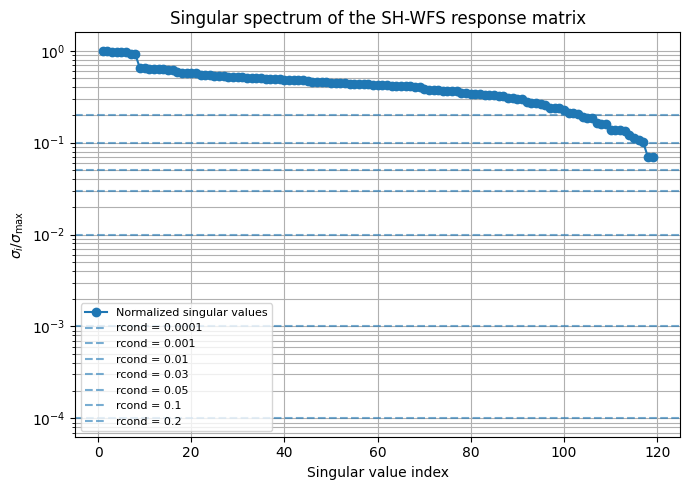

In [21]:
plt.figure(figsize=(7, 5))

plt.semilogy(
    np.arange(1, len(svals_norm) + 1),
    svals_norm,
    marker="o",
    label="Normalized singular values",
)

for rcond in [1e-4, 1e-3, 1e-2, 3e-2, 5e-2, 1e-1, 2e-1]:
    plt.axhline(
        rcond,
        linestyle="--",
        alpha=0.6,
        label=f"rcond = {rcond:g}",
    )

plt.xlabel("Singular value index")
plt.ylabel(r"$\sigma_i / \sigma_{\max}$")
plt.title("Singular spectrum of the SH-WFS response matrix")
plt.grid(True, which="both")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Singular-spectrum diagnostic

The singular-value spectrum shows which modal directions are strongly or weakly sensed by the Shack-Hartmann WFS.

Large singular values correspond to modal combinations that produce strong and distinguishable slope signals. Small singular values correspond to weakly sensed or nearly degenerate modal directions. Directly inverting these small singular values can amplify measurement noise.

The TSVD cutoff `rcond` removes directions with

\[
\sigma_i \leq rcond \cdot \sigma_{\max}.
\]

Therefore, TSVD only changes the reconstruction when the cutoff is larger than some normalized singular values.

In [22]:
rcond_values = np.array([
    1e-8,
    1e-5,
    1e-4,
    1e-3,
    3e-3,
    1e-2,
    3e-2,
    5e-2,
    8e-2,
    1e-1,
    1.5e-1,
    2e-1,
    3e-1,
    5e-1,
])

tsvd_results = []

for rcond in rcond_values:
    result = run_tsvd_reconstruction(
        W_atm,
        X,
        Y,
        rho,
        theta,
        mask,
        max_radial_order=max_radial_order,
        n_lenslets=n_lenslets,
        noise_std=noise_std,
        seed=2,
        rcond=rcond,
    )

    tsvd_results.append(result)

    print(
        f"rcond={rcond:.2e}, "
        f"kept={result['info']['n_kept']:3d}/{result['info']['n_total']:3d}, "
        f"residual RMS={result['residual_rms']:.4f} rad, "
        f"Strehl={result['strehl']:.4f}, "
        f"effective cond={result['info']['condition_effective']:.2e}"
    )

rcond=1.00e-08, kept=119/119, residual RMS=0.2892 rad, Strehl=0.9231, effective cond=1.42e+01
rcond=1.00e-05, kept=119/119, residual RMS=0.2892 rad, Strehl=0.9231, effective cond=1.42e+01
rcond=1.00e-04, kept=119/119, residual RMS=0.2892 rad, Strehl=0.9231, effective cond=1.42e+01
rcond=1.00e-03, kept=119/119, residual RMS=0.2892 rad, Strehl=0.9231, effective cond=1.42e+01
rcond=3.00e-03, kept=119/119, residual RMS=0.2892 rad, Strehl=0.9231, effective cond=1.42e+01
rcond=1.00e-02, kept=119/119, residual RMS=0.2892 rad, Strehl=0.9231, effective cond=1.42e+01
rcond=3.00e-02, kept=119/119, residual RMS=0.2892 rad, Strehl=0.9231, effective cond=1.42e+01
rcond=5.00e-02, kept=119/119, residual RMS=0.2892 rad, Strehl=0.9231, effective cond=1.42e+01
rcond=8.00e-02, kept=117/119, residual RMS=0.5437 rad, Strehl=0.9072, effective cond=9.95e+00
rcond=1.00e-01, kept=117/119, residual RMS=0.5437 rad, Strehl=0.9072, effective cond=9.95e+00
rcond=1.50e-01, kept=109/119, residual RMS=0.7509 rad, Streh

In [23]:
residual_tsvd = np.array([
    r["residual_rms"] for r in tsvd_results
])

strehl_tsvd = np.array([
    r["strehl"] for r in tsvd_results
])

n_kept_tsvd = np.array([
    r["info"]["n_kept"] for r in tsvd_results
])

cond_eff_tsvd = np.array([
    r["info"]["condition_effective"] for r in tsvd_results
])

print("rcond values:")
print(rcond_values)

print("\nResidual RMS:")
print(residual_tsvd)

print("\nStrehl:")
print(strehl_tsvd)

print("\nNumber of kept singular directions:")
print(n_kept_tsvd)

print("\nEffective condition number:")
print(cond_eff_tsvd)

rcond values:
[1.0e-08 1.0e-05 1.0e-04 1.0e-03 3.0e-03 1.0e-02 3.0e-02 5.0e-02 8.0e-02
 1.0e-01 1.5e-01 2.0e-01 3.0e-01 5.0e-01]

Residual RMS:
[0.28916654 0.28916654 0.28916654 0.28916654 0.28916654 0.28916654
 0.28916654 0.28916654 0.54374181 0.54374181 0.75090584 0.83774856
 0.94756318 0.98684851]

Strehl:
[0.92312988 0.92312988 0.92312988 0.92312988 0.92312988 0.92312988
 0.92312988 0.92312988 0.90719095 0.90719095 0.69603814 0.62817288
 0.50535666 0.46264291]

Number of kept singular directions:
[119 119 119 119 119 119 119 119 117 117 109 103  89  35]

Effective condition number:
[14.22094593 14.22094593 14.22094593 14.22094593 14.22094593 14.22094593
 14.22094593 14.22094593  9.95239495  9.95239495  6.21792998  4.88341132
  3.26182934  1.98063954]


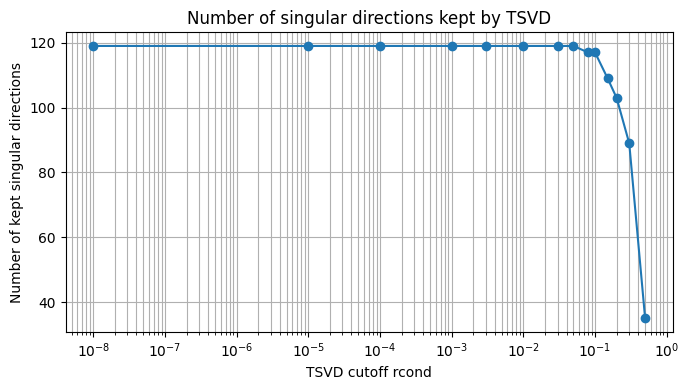

In [24]:
plt.figure(figsize=(7, 4))

plt.semilogx(
    rcond_values,
    n_kept_tsvd,
    marker="o",
)

plt.xlabel("TSVD cutoff rcond")
plt.ylabel("Number of kept singular directions")
plt.title("Number of singular directions kept by TSVD")
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

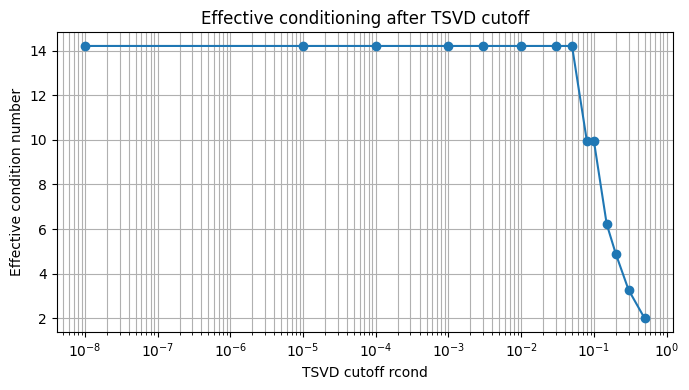

In [25]:
plt.figure(figsize=(7, 4))

plt.semilogx(
    rcond_values,
    cond_eff_tsvd,
    marker="o",
)

plt.xlabel("TSVD cutoff rcond")
plt.ylabel("Effective condition number")
plt.title("Effective conditioning after TSVD cutoff")
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

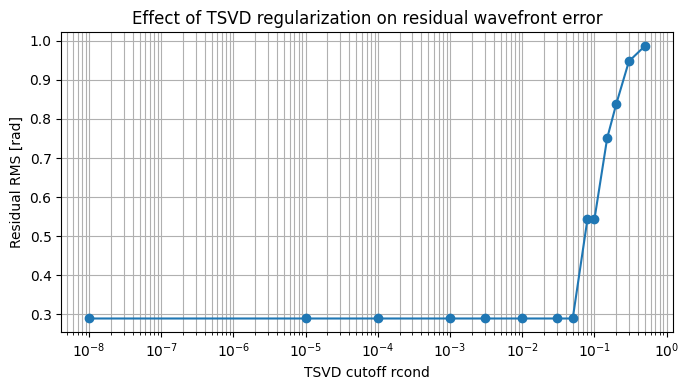

In [26]:
plt.figure(figsize=(7, 4))

plt.semilogx(
    rcond_values,
    residual_tsvd,
    marker="o",
)

plt.xlabel("TSVD cutoff rcond")
plt.ylabel("Residual RMS [rad]")
plt.title("Effect of TSVD regularization on residual wavefront error")
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

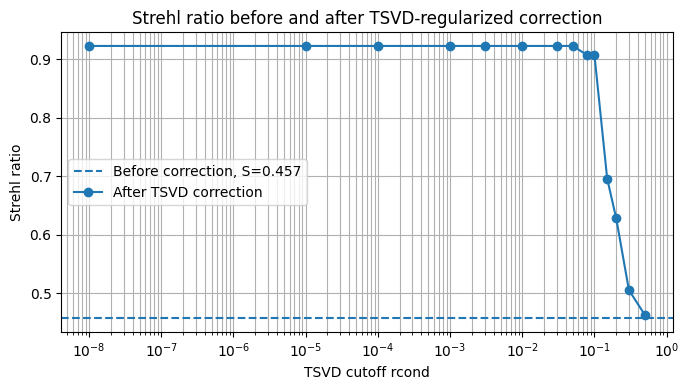

In [27]:
strehl_before = strehl_ratio(
    W_atm,
    mask,
    pad_factor=4,
)

plt.figure(figsize=(7, 4))

plt.axhline(
    strehl_before,
    linestyle="--",
    label=f"Before correction, S={strehl_before:.3f}",
)

plt.semilogx(
    rcond_values,
    strehl_tsvd,
    marker="o",
    label="After TSVD correction",
)

plt.xlabel("TSVD cutoff rcond")
plt.ylabel("Strehl ratio")
plt.title("Strehl ratio before and after TSVD-regularized correction")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
best_idx_strehl = np.argmax(strehl_tsvd)
best_idx_rms = np.argmin(residual_tsvd)

print("Best TSVD cutoff based on Strehl ratio")
print("--------------------------------------")
print(f"best rcond:       {rcond_values[best_idx_strehl]:.2e}")
print(f"kept directions:  {n_kept_tsvd[best_idx_strehl]}/{tsvd_results[best_idx_strehl]['info']['n_total']}")
print(f"residual RMS:     {residual_tsvd[best_idx_strehl]:.4f} rad")
print(f"Strehl ratio:     {strehl_tsvd[best_idx_strehl]:.4f}")
print(f"effective cond:   {cond_eff_tsvd[best_idx_strehl]:.2e}")

print()

print("Best TSVD cutoff based on residual RMS")
print("--------------------------------------")
print(f"best rcond:       {rcond_values[best_idx_rms]:.2e}")
print(f"kept directions:  {n_kept_tsvd[best_idx_rms]}/{tsvd_results[best_idx_rms]['info']['n_total']}")
print(f"residual RMS:     {residual_tsvd[best_idx_rms]:.4f} rad")
print(f"Strehl ratio:     {strehl_tsvd[best_idx_rms]:.4f}")
print(f"effective cond:   {cond_eff_tsvd[best_idx_rms]:.2e}")

Best TSVD cutoff based on Strehl ratio
--------------------------------------
best rcond:       1.00e-08
kept directions:  119/119
residual RMS:     0.2892 rad
Strehl ratio:     0.9231
effective cond:   1.42e+01

Best TSVD cutoff based on residual RMS
--------------------------------------
best rcond:       1.00e-08
kept directions:  119/119
residual RMS:     0.2892 rad
Strehl ratio:     0.9231
effective cond:   1.42e+01


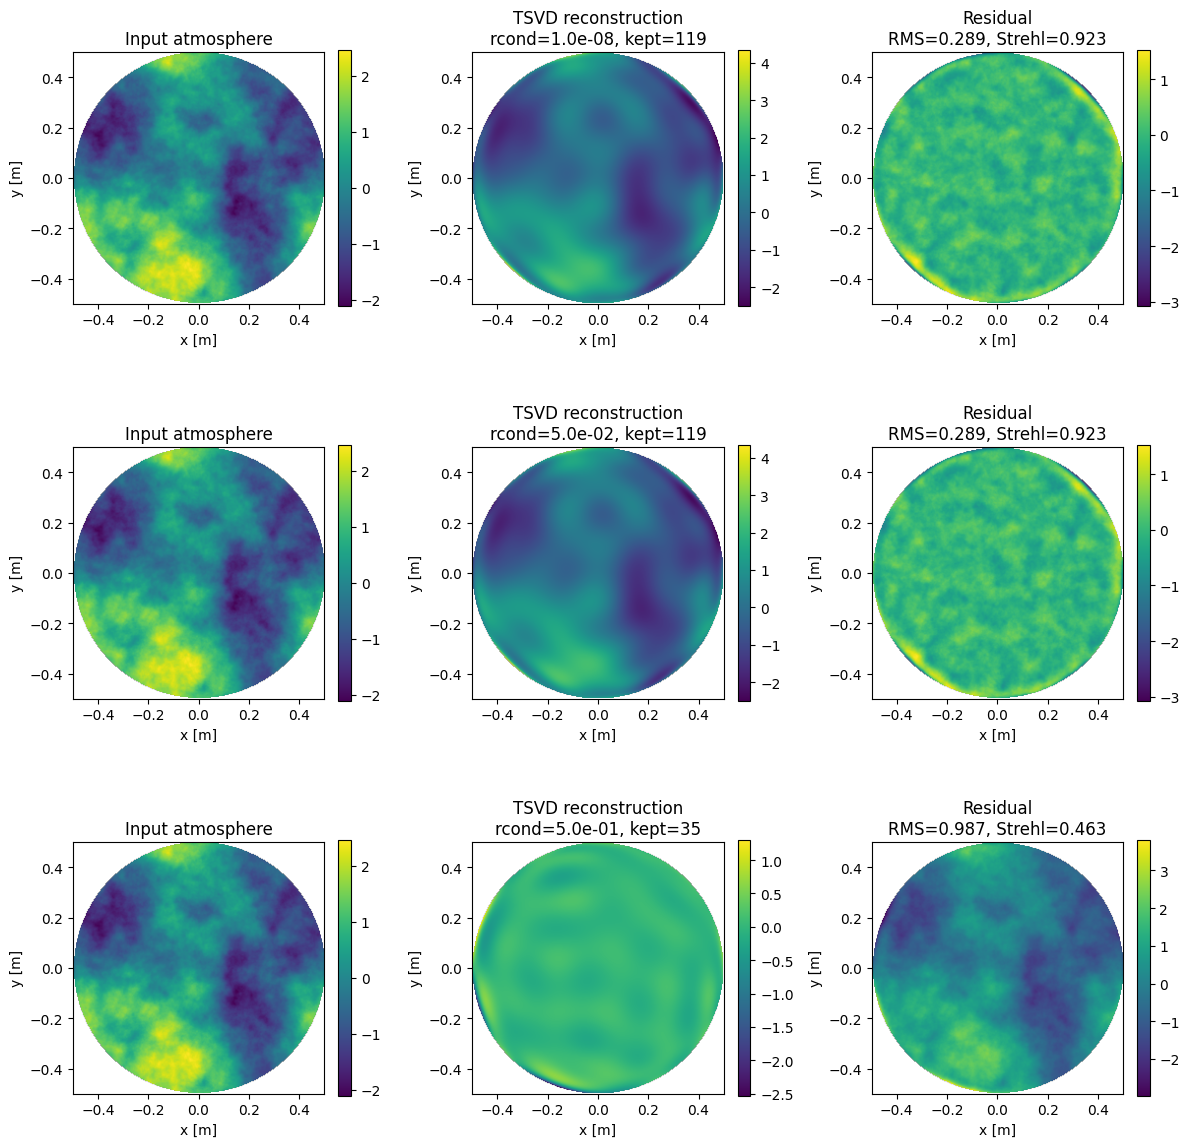

In [29]:
selected_rconds = [
    rcond_values[0],
    rcond_values[len(rcond_values) // 2],
    rcond_values[-1],
]

selected_indices = [
    np.where(rcond_values == r)[0][0] for r in selected_rconds
]

fig, axes = plt.subplots(
    len(selected_indices),
    3,
    figsize=(12, 4 * len(selected_indices)),
)

for row, idx in enumerate(selected_indices):
    result = tsvd_results[idx]
    rcond = rcond_values[idx]

    W_rec = result["W_rec"]
    res = result["residual"]

    im0 = axes[row, 0].imshow(
        W_atm,
        extent=extent,
        origin="lower",
    )
    axes[row, 0].set_title("Input atmosphere")
    axes[row, 0].set_xlabel("x [m]")
    axes[row, 0].set_ylabel("y [m]")
    plt.colorbar(im0, ax=axes[row, 0], fraction=0.046)

    im1 = axes[row, 1].imshow(
        W_rec,
        extent=extent,
        origin="lower",
    )
    axes[row, 1].set_title(
        f"TSVD reconstruction\n"
        f"rcond={rcond:.1e}, kept={result['info']['n_kept']}"
    )
    axes[row, 1].set_xlabel("x [m]")
    axes[row, 1].set_ylabel("y [m]")
    plt.colorbar(im1, ax=axes[row, 1], fraction=0.046)

    im2 = axes[row, 2].imshow(
        res,
        extent=extent,
        origin="lower",
    )
    axes[row, 2].set_title(
        f"Residual\n"
        f"RMS={result['residual_rms']:.3f}, Strehl={result['strehl']:.3f}"
    )
    axes[row, 2].set_xlabel("x [m]")
    axes[row, 2].set_ylabel("y [m]")
    plt.colorbar(im2, ax=axes[row, 2], fraction=0.046)

plt.tight_layout()
plt.show()

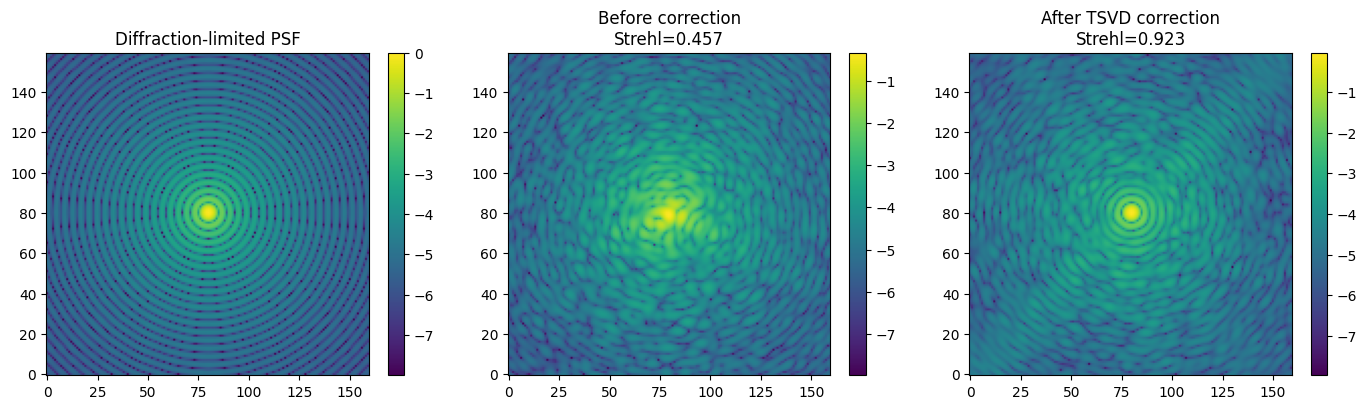

In [30]:
best_result = tsvd_results[best_idx_strehl]

psf_ideal = compute_psf_from_phase(
    np.zeros_like(W_atm),
    mask,
    pad_factor=4,
)

psf_before = compute_psf_from_phase(
    W_atm,
    mask,
    pad_factor=4,
)

psf_after = compute_psf_from_phase(
    best_result["residual"],
    mask,
    pad_factor=4,
)

reference_peak = np.max(psf_ideal)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

crop = 80
center = psf_ideal.shape[0] // 2
sl = slice(center - crop, center + crop)

im0 = axes[0].imshow(
    np.log10(psf_ideal[sl, sl] / reference_peak + 1e-8),
    origin="lower",
)
axes[0].set_title("Diffraction-limited PSF")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(
    np.log10(psf_before[sl, sl] / reference_peak + 1e-8),
    origin="lower",
)
axes[1].set_title(f"Before correction\nStrehl={strehl_before:.3f}")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(
    np.log10(psf_after[sl, sl] / reference_peak + 1e-8),
    origin="lower",
)
axes[2].set_title(
    f"After TSVD correction\n"
    f"Strehl={best_result['strehl']:.3f}"
)
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

## Interpretation of the TSVD Regularization Test

The TSVD scan shows that, for the current reconstruction setup, the best performance is obtained when all singular directions are retained. For cutoffs up to approximately `rcond = 0.05`, all 119 singular directions are kept, and the residual RMS and Strehl ratio remain unchanged. This is because the smallest normalized singular values are still larger than the cutoff.

Once the cutoff reaches approximately `rcond = 0.08`, the first weak singular directions are removed. The effective condition number decreases, but the residual RMS increases and the Strehl ratio decreases. This indicates that the discarded directions are not dominated by measurement noise; they still contain useful atmospheric wavefront information.

Therefore, in this case, TSVD regularization does not improve the reconstruction. The response matrix is sufficiently well-conditioned, and the measurement noise is not large enough for noise amplification to dominate the error budget. Stronger regularization reduces the effective correction order and increases the modal fitting error.

This result demonstrates an important point: regularization is not automatically beneficial. It is useful only when the weak singular directions amplify noise more than they contribute useful signal. In the present simulation, keeping all modes gives the lowest residual wavefront error and the highest Strehl ratio.
